In [1]:
import pandas as pd

df = pd.read_csv('car_purchasing.csv', encoding='utf-8-sig')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer name        500 non-null    str    
 1   customer e-mail      500 non-null    str    
 2   country              500 non-null    str    
 3   gender               500 non-null    int64  
 4   age                  500 non-null    float64
 5   annual Salary        500 non-null    float64
 6   credit card debt     500 non-null    float64
 7   net worth            500 non-null    float64
 8   car purchase amount  500 non-null    float64
dtypes: float64(5), int64(1), str(3)
memory usage: 60.0 KB


In [2]:
df['debt_to_income'] = df['credit card debt'] / df['annual Salary']

In [3]:
X = df[['age', 'annual Salary', 'credit card debt', 'net worth', 'debt_to_income']]
y = df['car purchase amount']
X.head()

,age,annual Salary,credit card debt,net worth,debt_to_income
0,41.851720,62812.09301,11609.380910,238961.2505,0.184827
1,40.870623,66646.89292,9572.957136,530973.9078,0.143637
2,43.152897,53798.55112,11160.355060,638467.1773,0.207447
3,58.271369,79370.03798,14426.164850,548599.0524,0.181758
4,57.313749,59729.15130,5358.712177,560304.0671,0.089717


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[6764.24,6685.21, -0.05,5082.4 , -0.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.395e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[27.55,20.64,20.19,19.7 , 4.38]"


In [7]:
y_pred = lr.predict(X_test_scaled)

In [8]:
nuovo_cliente = X_test.iloc[0:1]
nuovo_cliente_scaled = scaler.transform(nuovo_cliente)
predizione = lr.predict(nuovo_cliente_scaled)
print(f"Cliente: {nuovo_cliente}")
print(f"Predizione di spesa in auto: ${predizione[0]:,.2f}")

Cliente:            age  annual Salary  credit card debt    net worth  debt_to_income
361  36.126918    74420.10254       10274.13558  551344.3365        0.138056
Predizione di spesa in auto: $46,084.51


In [9]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:,.2f}")

rmse = np.sqrt(mse)
print(f"RMSE: ${rmse:,.2f}")


MSE: 2.07
RMSE: $1.44


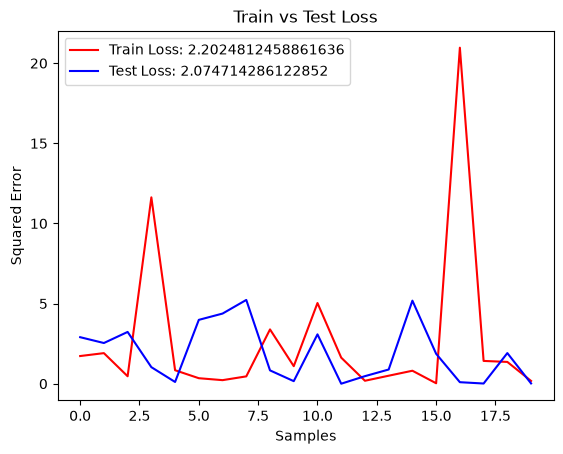

In [10]:
from matplotlib import pyplot as plt
from sklearn.metrics import mean_squared_error as mse
import numpy as np
y_pred_train = lr.predict(X_train_scaled)
y_pred_test = lr.predict(X_test_scaled)
train_errors = (y_train - y_pred_train) ** 2
test_errors = (y_test - y_pred_test) ** 2
x_train = np.arange(len(train_errors))
x_test = np.arange(len(test_errors))

plt.plot(x_train[:20], train_errors[:20], color="red", label=f"Train Loss: {train_errors.mean()}")
plt.plot(x_test[:20], test_errors[:20], color="blue", label=f"Test Loss: {test_errors.mean()}")
plt.xlabel("Samples")
plt.ylabel("Squared Error")
plt.title("Train vs Test Loss")
plt.legend()

plt.show()